<a href="https://colab.research.google.com/github/JiawenAi/MSSP6070/blob/main/WeeklyModules/Week07/weekly_activity_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
from google.colab import userdata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import subprocess
import os

github_token = userdata.get('Git_key')

owner = 'JiawenAi'
repository = 'MSSP6070'

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

subprocess.run(['git', 'clone', clone_url])

os.chdir(repository)

df = pd.read_csv("data/InternetSales.csv",
    encoding="cp1252")
df.head()

/tmp/ipykernel_2018/1538553757.py:20: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/InternetSales.csv",


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [15]:
plt.rc('figure', figsize=(10, 6))
np.set_printoptions(precision=4, suppress=True)

In [16]:
df.columns.tolist()

['ID',
 'CustomerKey',
 'GeographyKey',
 'City',
 'CountryRegionCode',
 'EnglishCountryRegionName',
 'CustomerAlternateKey',
 'Title',
 'FirstName',
 'MiddleName',
 'LastName',
 'NameStyle',
 'BirthDate',
 'MaritalStatus',
 'Suffix',
 'Gender',
 'EmailAddress',
 'YearlyIncome',
 'TotalChildren',
 'NumberChildrenAtHome',
 'EnglishEducation',
 'SpanishEducation',
 'FrenchEducation',
 'EnglishOccupation',
 'SpanishOccupation',
 'FrenchOccupation',
 'HouseOwnerFlag',
 'NumberCarsOwned',
 'AddressLine1',
 'AddressLine2',
 'Phone',
 'DateFirstPurchase',
 'CommuteDistance',
 'ProductKey',
 'EnglishProductName',
 'OrderDateKey',
 'DueDateKey',
 'ShipDateKey',
 'CustomerKey.1',
 'PromotionKey',
 'CurrencyKey',
 'SalesTerritoryKey',
 'SalesOrderNumber',
 'SalesOrderLineNumber',
 'RevisionNumber',
 'OrderQuantity',
 'UnitPrice',
 'ExtendedAmount',
 'UnitPriceDiscountPct',
 'DiscountAmount',
 'ProductStandardCost',
 'TotalProductCost',
 'SalesAmount',
 'TaxAmt',
 'Freight',
 'CarrierTrackingNumber

In [17]:
# Convert OrderDate to datetime
df['OrderDate'] = pd.to_datetime(df['OrderDate'])

# Year column
df['Year'] = df['OrderDate'].dt.year

df[['OrderDate', 'Year', 'SalesAmount']].head()

,OrderDate,Year,SalesAmount
0,2011-01-19,2011,3399.99
1,2013-01-18,2013,2319.99
2,2013-01-18,2013,21.98
3,2013-05-03,2013,2384.07
4,2013-05-03,2013,28.99


In [18]:
yearlysales = df.groupby('Year')['SalesAmount'].sum()
yearlysales

,SalesAmount
Year,
2010,4.342104e+04
2011,7.075526e+06
2012,5.842485e+06
2013,1.635155e+07
2014,4.569472e+04


In [19]:
df['OrderDate'].min(), df['OrderDate'].max()

(Timestamp('2010-12-29 00:00:00'), Timestamp('2014-01-28 00:00:00'))

In [20]:
df.groupby('Year')['OrderDate'].agg(['min', 'max', 'count'])

,min,max,count
Year,,,
2010,2010-12-29,2010-12-31,14
2011,2011-01-01,2011-12-31,2216
2012,2012-01-01,2012-12-31,3397
2013,2013-01-01,2013-12-31,52801
2014,2014-01-01,2014-01-28,1970


becasue there are only small amount values in the year 2010 and 2014,  the bar chart might not be showing their values in terms of a obvious size of the bar

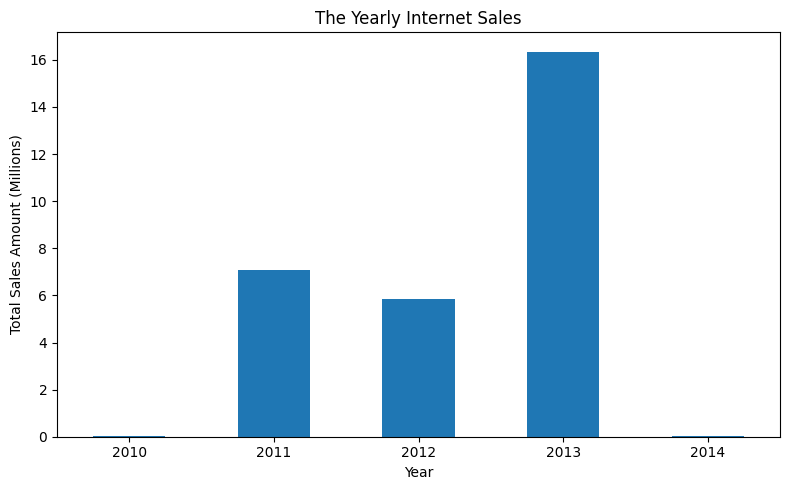

In [24]:
yearlysales_millions = yearlysales / 1_000_000

plt.figure(figsize=(8, 5))

yearlysales_millions.plot(kind='bar')

plt.xlabel('Year')
plt.ylabel('Total Sales Amount (Millions)')
plt.title('The Yearly Internet Sales')
plt.xticks(rotation=0)

#since we know the region is Austrilia but there's
#no explict statement on the currency
#I won't say its in AUD

plt.tight_layout()

#Save as PDF
plt.savefig('WeeklyModules/Week07/yearlysales.pdf')
plt.show()